> **AI use declaration.** Parts of the code and text in this notebook were generated with the help of an AI assistant (Claude, by Anthropic), as allowed for this assignment. I (Kularathna G.G.A.S., 224110P) ran every cell, checked the outputs and the numbers quoted in the text, and made the final modelling decisions.


# 01 - Data Understanding & Validation

First proper look at the raw weekly dengue data before any cleaning or modelling. The aim is to understand what's in the file and note down any problems to deal with in notebook 02.

**Data:** `srilanka_weekly_data` from [denguedatahub](https://github.com/thiyangt/denguedatahub) (Dr. Thiyanga S. Talagala). Weekly dengue case counts per district, compiled from the Weekly Epidemiological Reports of the Epidemiology Unit, Ministry of Health.

Nothing gets fixed or dropped here, only checked. The raw file isn't touched; at the end a copy with proper dtypes is saved to `dataset/processed/`.

In [1]:
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("../dataset")
RAW_PATH = DATA_DIR / "raw" / "srilanka_weekly_data.csv"
OUT_PATH = DATA_DIR / "processed" / "01_validated_weekly_data.csv"

## Load the data

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print(df_raw.shape)
df_raw.head(10)

(26753, 6)


,year,week,start.date,end.date,district,cases
0,2006,52,12/23/2006,12/29/2006,Colombo,71
1,2006,52,12/23/2006,12/29/2006,Gampaha,12
2,2006,52,12/23/2006,12/29/2006,Kalutara,12
3,2006,52,12/23/2006,12/29/2006,Kandy,20
4,2006,52,12/23/2006,12/29/2006,Matale,4
5,2006,52,12/23/2006,12/29/2006,NuwaraEliya,1
6,2006,52,12/23/2006,12/29/2006,Galle,1
7,2006,52,12/23/2006,12/29/2006,Hambanthota,1
8,2006,52,12/23/2006,12/29/2006,Matara,11
9,2006,52,12/23/2006,12/29/2006,Jaffna,0


In [ ]:
# file hash - so can tell later if the raw file was re-downloaded or edited
hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()

'dfc21d7378486a7256554ffe6dc813cf634629717280eae533488e40408262b7'

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 26753 entries, 0 to 26752
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   year        26753 non-null  int64
 1   week        26753 non-null  int64
 2   start.date  26753 non-null  str  
 3   end.date    26753 non-null  str  
 4   district    26753 non-null  str  
 5   cases       26753 non-null  int64
dtypes: int64(3), str(3)
memory usage: 1.9 MB


26,753 rows and 6 columns. No nulls in any column, and `year`, `week` and `cases` were read as integers straight away, so there's no stray text in the numeric columns.

The two date columns are still strings - need to convert them.

## Dates

In [5]:
df = df_raw.copy()
df["start_date"] = pd.to_datetime(df["start.date"], format="%m/%d/%Y", errors="coerce")
df["end_date"] = pd.to_datetime(df["end.date"], format="%m/%d/%Y", errors="coerce")

df[["start_date", "end_date"]].isna().sum()

start_date    442
end_date      442
dtype: int64

Some dates didn't parse. Let's see which ones:

In [6]:
bad_dates = df[df["start_date"].isna()]
print(len(bad_dates), "rows")
bad_dates[["year", "week", "start.date", "end.date"]].drop_duplicates(["year", "week"])

442 rows


,year,week,start.date,end.date
26311,2026,21,2026-05-18,2026-05-24
26337,2026,22,2026-05-25,2026-05-31
26363,2026,23,2026-06-01,2026-06-07
26389,2026,24,2026-06-08,2026-06-14
26415,2026,25,2026-06-15,2026-06-21
26441,2026,26,2026-06-22,2026-06-28
26467,2026,27,2026-06-29,2026-07-05
26493,2026,28,2026-07-06,2026-07-12
26519,2026,29,2026-07-13,2026-07-19
26545,2026,30,2026-07-20,2026-07-26


These are all the most recent weeks of 2026 and they use `YYYY-MM-DD` instead of `M/D/YYYY` - looks like the newer rows were added in a different format. 442 rows = 17 weeks x 26 districts, so it's the whole block, not random rows.

Easy fix: parse those with the ISO format.

In [7]:
df["start_date"] = df["start_date"].fillna(pd.to_datetime(df["start.date"], format="%Y-%m-%d", errors="coerce"))
df["end_date"] = df["end_date"].fillna(pd.to_datetime(df["end.date"], format="%Y-%m-%d", errors="coerce"))

df[["start_date", "end_date"]].isna().sum()

start_date    0
end_date      0
dtype: int64

In [8]:
# all dates parse now - drop the original string columns
df = df[["year", "week", "start_date", "end_date", "district", "cases"]]
df.dtypes

year                   int64
week                   int64
start_date    datetime64[us]
end_date      datetime64[us]
district                 str
cases                  int64
dtype: object

## Missing values and duplicates

In [9]:
df.isna().sum()

year          0
week          0
start_date    0
end_date      0
district      0
cases         0
dtype: int64

In [10]:
print("exact duplicate rows:", df_raw.duplicated().sum())
print("same district + start date:", df.duplicated(["district", "start_date"]).sum())
print("same district + year/week:", df.duplicated(["district", "year", "week"]).sum())

exact duplicate rows: 0
same district + start date: 0
same district + year/week: 0


No missing values and no duplicates - each district appears at most once per week.

## Districts

In [11]:
print(df["district"].nunique(), "districts")
df["district"].value_counts().sort_index()

26 districts


district
Ampara          1029
Anuradhapura    1029
Badulla         1029
Batticaloa      1029
Colombo         1029
Galle           1029
Gampaha         1029
Hambanthota     1029
Jaffna          1029
Kalmune         1029
Kalutara        1029
Kandy           1029
Kegalle         1029
Kilinochchi     1029
Kurunegala      1029
Mannar          1029
Matale          1029
Matara          1029
Monaragala      1029
Mullaitivu      1029
NuwaraEliya     1029
Polonnaruwa     1029
Puttalam        1028
Ratnapura       1029
Trincomalee     1029
Vavuniya        1029
Name: count, dtype: int64

In [12]:
# check for names that only differ by case or spaces (e.g. "Colombo" vs "colombo ")
names = df["district"].unique()
len(names), len({n.strip().lower() for n in names})

(26, 26)

26 reporting units: the 25 districts plus Kalmunai, which the Epidemiology Unit reports as a separate RDHS division (spelt `Kalmune` in this file). No spelling or whitespace variants.

Every district has 1029 rows except **Puttalam with 1028**, so Puttalam is missing one week. Which one?

In [13]:
all_weeks = set(df["start_date"])
puttalam_weeks = set(df.loc[df["district"] == "Puttalam", "start_date"])
missing_weeks = all_weeks - puttalam_weeks

df.loc[df["start_date"].isin(missing_weeks), ["year", "week", "start_date", "end_date"]].drop_duplicates()

,year,week,start_date,end_date
25948,2026,7,2026-02-09,2026-02-15


Puttalam has no row for **2026 week 7** (Feb 9-15). It's just that one week; every other district has it.

## Date range and week continuity

In [14]:
print("from", df["start_date"].min().date(), "to", df["end_date"].max().date())
print("weeks:", df["start_date"].nunique())

from 2006-12-23 to 2026-09-13
weeks: 1029


Each row should be one week, so `end_date` should be `start_date + 6 days`.

In [15]:
span = (df["end_date"] - df["start_date"]).dt.days
span.value_counts()

6    26701
7       26
5       26
Name: count, dtype: int64

In [16]:
df.loc[span != 6, ["year", "week", "start_date", "end_date"]].drop_duplicates()

,year,week,start_date,end_date
3146,2009,17,2009-04-18,2009-04-25
3276,2009,22,2009-05-24,2009-05-29


Now check the gaps between consecutive weeks - should always be 7 days.

In [17]:
weeks = df.drop_duplicates("start_date").sort_values("start_date")[["year", "week", "start_date", "end_date"]]
weeks["gap_days"] = weeks["start_date"].diff().dt.days

weeks[weeks["gap_days"].notna() & (weeks["gap_days"] != 7)]

,year,week,start_date,end_date,gap_days
3172,2009,18,2009-04-26,2009-05-02,8.0
3302,2009,23,2009-05-30,2009-06-05,6.0
25792,2026,1,2025-12-29,2026-01-04,9.0


A few irregular weeks:
- **2009 week 17** runs Apr 18-25, so it's 8 days long. That pushes weeks 18-21 back by a day, and then **week 22** (May 24-29) is only 6 days, which brings the calendar back in line.
- **Dec 2025**: the week starting 2025-12-20 ends on the 26th, but the next one only starts on the 29th, so 27-28 Dec aren't covered by any week.

These are small and most likely just how the reports were published, but worth keeping in mind for anything that assumes a perfectly regular weekly series.

## Week numbers

In [18]:
df["week"].agg(["min", "max"])

min     1
max    53
Name: week, dtype: int64

In [19]:
weeks_per_year = df.groupby("year")["week"].agg(["min", "max", "nunique"])
weeks_per_year

,min,max,nunique
year,,,
2006,52,52,1
2007,1,52,52
2008,1,52,52
2009,1,53,53
2010,1,52,52
2011,1,52,52
2012,1,52,52
2013,1,52,52
2014,1,52,52


Does the `year` label actually match the dates? (Allowing for weeks that cross 31 Dec.)

In [20]:
weeks[(weeks["year"] != weeks["start_date"].dt.year) & (weeks["year"] != weeks["end_date"].dt.year)]

,year,week,start_date,end_date,gap_days
23062,2024,1,2023-12-23,2023-12-29,7.0
24414,2025,1,2024-12-21,2024-12-27,7.0
25766,2026,53,2025-12-20,2025-12-26,7.0


Week numbers are all between 1 and 53. Week 53 shows up in 2009, 2016, 2021 and 2026.

A few things don't line up though:
- **2024 week 1** and **2025 week 1** are dated in late December of the previous year (whole week before 1 Jan).
- **2026 week 53** is dated 2025-12-20 to 2025-12-26 - that looks like it should be 2025 week 53 (or 52), not 2026.
- **2023** only has weeks 1-51. Given 2024 week 1 starts on 2023-12-23, the labelling around that year end is probably off by one.
- **2026** has 38 week numbers (1-37 plus the odd 53), which is just because the data stops in September 2026.

So `year`/`week` labels aren't fully reliable around year ends. `start_date` is the safer key for ordering and joining.

## Case counts

In [21]:
df["cases"].describe()

count    26753.000000
mean        33.586887
std         86.797951
min          0.000000
25%          2.000000
50%          9.000000
75%         30.000000
max       2631.000000
Name: cases, dtype: float64

In [22]:
print("negative:", (df["cases"] < 0).sum())
print(f"zero: {(df['cases'] == 0).sum()} ({(df['cases'] == 0).mean():.1%} of rows)")

negative: 0
zero: 3641 (13.6% of rows)


In [23]:
df.groupby("district")["cases"].describe().sort_values("mean", ascending=False).round(1)

,count,mean,std,min,25%,50%,75%,max
district,,,,,,,,
Colombo,1029.0,188.9,222.7,0.0,53.0,131.0,252.0,1972.0
Gampaha,1029.0,115.4,215.3,0.0,25.0,58.0,123.0,2631.0
Kandy,1029.0,71.1,109.3,0.0,15.0,40.0,74.0,1062.0
Kalutara,1029.0,54.8,83.0,0.0,15.0,32.0,60.0,866.0
Jaffna,1029.0,44.7,89.7,0.0,6.0,18.0,48.0,931.0
Kurunegala,1029.0,43.9,64.6,0.0,14.0,26.0,50.0,681.0
Ratnapura,1029.0,43.5,67.1,0.0,10.0,26.0,54.0,920.0
Galle,1029.0,36.4,56.4,0.0,6.0,18.0,41.0,742.0
Kegalle,1029.0,35.9,62.9,0.0,10.0,21.0,39.0,807.0


No negative counts. About 14% of rows are zero, which is expected - most of them are the low-incidence districts (Mullaitivu, Kilinochchi, Mannar, Ampara...). Colombo and Gampaha are far ahead of everyone else.

The max values are huge compared to the medians, so let's look at the spikes. Using a simple per-district rule: anything above Q3 + 3*IQR.

In [24]:
q1 = df.groupby("district")["cases"].transform(lambda x: x.quantile(0.25))
q3 = df.groupby("district")["cases"].transform(lambda x: x.quantile(0.75))
upper = q3 + 3 * (q3 - q1)

spikes = df[df["cases"] > upper]
print(len(spikes), "rows flagged", f"({len(spikes) / len(df):.1%})")
spikes.sort_values("cases", ascending=False).head(15)

1060 rows flagged (4.0%)


,year,week,start_date,end_date,district,cases
14301,2017,28,2017-07-08,2017-07-14,Gampaha,2631
14327,2017,29,2017-07-15,2017-07-21,Gampaha,2471
14353,2017,30,2017-07-22,2017-07-28,Gampaha,2135
14326,2017,29,2017-07-15,2017-07-21,Colombo,1972
14352,2017,30,2017-07-22,2017-07-28,Colombo,1958
14275,2017,27,2017-07-01,2017-07-07,Gampaha,1802
14274,2017,27,2017-07-01,2017-07-07,Colombo,1779
14300,2017,28,2017-07-08,2017-07-14,Colombo,1762
14378,2017,31,2017-07-29,2017-08-04,Colombo,1713
26493,2026,28,2026-07-06,2026-07-12,Colombo,1625


In [25]:
spikes["year"].value_counts().sort_index()

year
2009     23
2010     26
2011      3
2012      2
2014     10
2015      1
2016      8
2017    394
2018     44
2019    156
2020     58
2021     18
2022     10
2023     70
2024     48
2025      6
2026    183
Name: count, dtype: int64

The biggest weeks are all from the **2017 epidemic** (Colombo and Gampaha, June-August) and the **mid-2026** wave. Most flagged rows by year are 2017, 2026 and 2019, which are known bad dengue years. These are real outbreaks, not data errors, and they're exactly what the model needs to learn, so they stay in.

## Quick plots

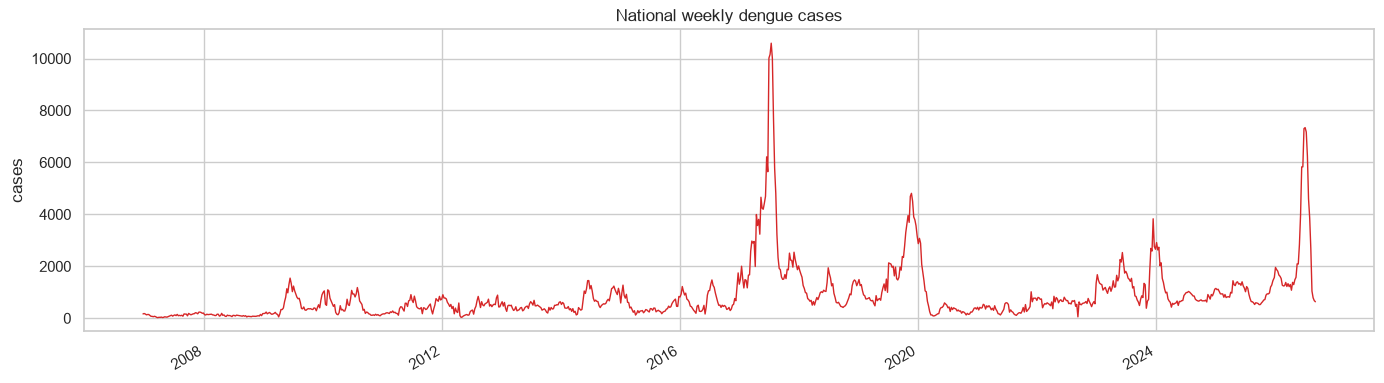

In [26]:
national = df.groupby("start_date")["cases"].sum()

fig, ax = plt.subplots(figsize=(14, 4))
national.plot(ax=ax, color="tab:red", lw=1)
ax.set_title("National weekly dengue cases")
ax.set_xlabel("")
ax.set_ylabel("cases")
plt.tight_layout()
plt.show()

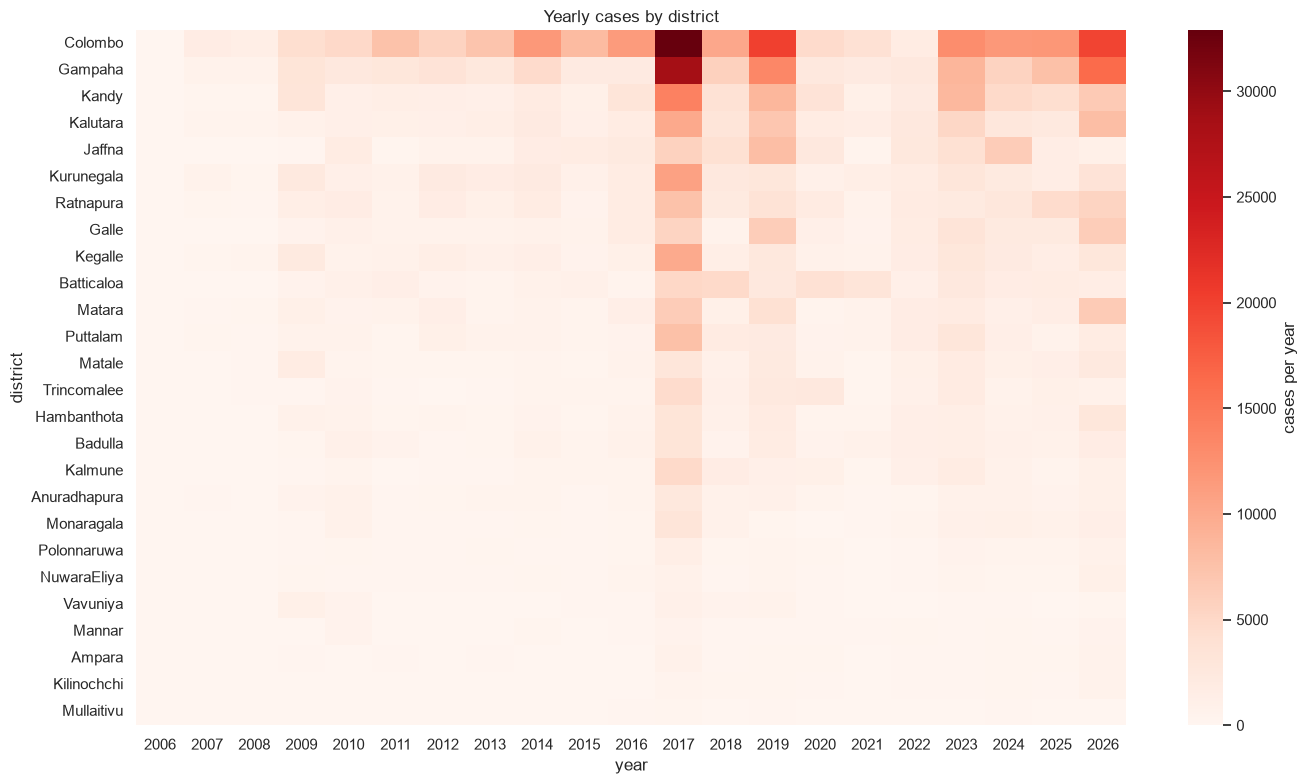

In [27]:
pivot = df.pivot_table(index="district", columns="year", values="cases", aggfunc="sum")
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap="Reds", ax=ax, cbar_kws={"label": "cases per year"})
ax.set_title("Yearly cases by district")
plt.tight_layout()
plt.show()

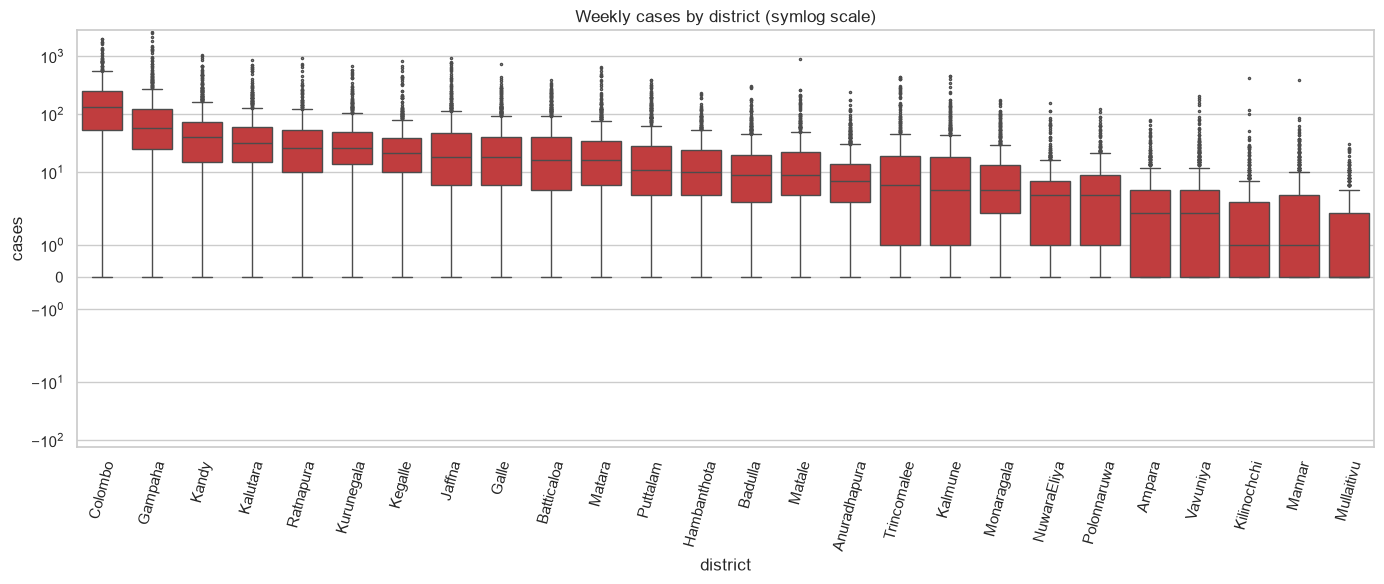

In [28]:
order = df.groupby("district")["cases"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x="district", y="cases", order=order, ax=ax, fliersize=1.5, color="tab:red")
ax.set_yscale("symlog")
ax.set_title("Weekly cases by district (symlog scale)")
ax.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

## Summary

The data is in good shape overall:
- 26,753 rows, 26 districts, weekly from 2006-12-23 to 2026-09-13 (1029 weeks)
- no missing values, no duplicates, no negative counts, all values parse

Things to handle in **notebook 02 (cleaning)**:

| Issue | Details |
|---|---|
| Mixed date formats | 442 rows (2026 weeks 21-37) use `YYYY-MM-DD`, the rest `M/D/YYYY`. Already handled when parsing above. |
| Missing Puttalam week | No Puttalam row for 2026 week 7 (Feb 9-15). Decide whether to fill it or leave it. |
| Irregular week lengths | 2009 week 17 is 8 days and week 22 is 6 days; 27-28 Dec 2025 not covered by any week. |
| Year/week labels around year end | 2024 wk 1 and 2025 wk 1 dated in the previous December; 2026 wk 53 dated Dec 2025; 2023 only has 51 weeks. Use `start_date` as the main time key. |
| Zero counts | ~14% of rows, mostly small districts. Real values, but relevant for model choice. |
| Outbreak spikes | 1,060 rows above Q3 + 3*IQR, mostly 2017, 2026 and 2019. Real outbreaks - keep. |

## Save

Save a copy with proper dtypes and clean column names. Same rows, same values - just sorted by week and district.

In [29]:
validated = df.sort_values(["start_date", "district"]).reset_index(drop=True)
assert len(validated) == len(df_raw)  # nothing should be dropped here

OUT_PATH.parent.mkdir(exist_ok=True)
validated.to_csv(OUT_PATH, index=False, date_format="%Y-%m-%d")
print("saved", len(validated), "rows to", OUT_PATH)

saved 26753 rows to ..\dataset\processed\01_validated_weekly_data.csv
